In [55]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score)

from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
COLS = ["pct_moda", "pct_eletronicos", "pct_casa", "pct_esportes", "pct_alimentos"]

df = pd.read_csv("base02_categorias_produtos.csv", encoding="utf-8")

df.head()

,id_cliente,pct_moda,pct_eletronicos,pct_casa,pct_esportes,pct_alimentos
0,C000001,8.47,9.03,67.39,4.19,10.93
1,C000002,34.93,3.36,4.68,49.38,7.65
2,C000003,1.83,65.62,11.23,8.62,12.70
3,C000004,3.90,6.83,59.86,5.88,23.53
4,C000005,11.19,44.74,7.65,20.06,16.36


In [56]:
display(df[COLS].describe().round(2))
print("Valores faltantes por coluna:")
print(df[COLS].isna().sum())

,pct_moda,pct_eletronicos,pct_casa,pct_esportes,pct_alimentos
count,2400.00,2400.00,2400.00,2400.00,2400.00
mean,22.84,23.34,22.07,15.42,16.34
std,23.52,24.94,21.19,14.75,12.80
min,0.62,0.46,0.77,0.29,2.52
25%,6.05,4.74,6.78,4.99,8.60
50%,10.54,7.72,10.52,8.63,11.40
75%,35.15,49.93,39.80,21.68,16.27
max,86.30,79.86,76.20,59.94,55.73


Valores faltantes por coluna:
pct_moda           0
pct_eletronicos    0
pct_casa           0
pct_esportes       0
pct_alimentos      0
dtype: int64


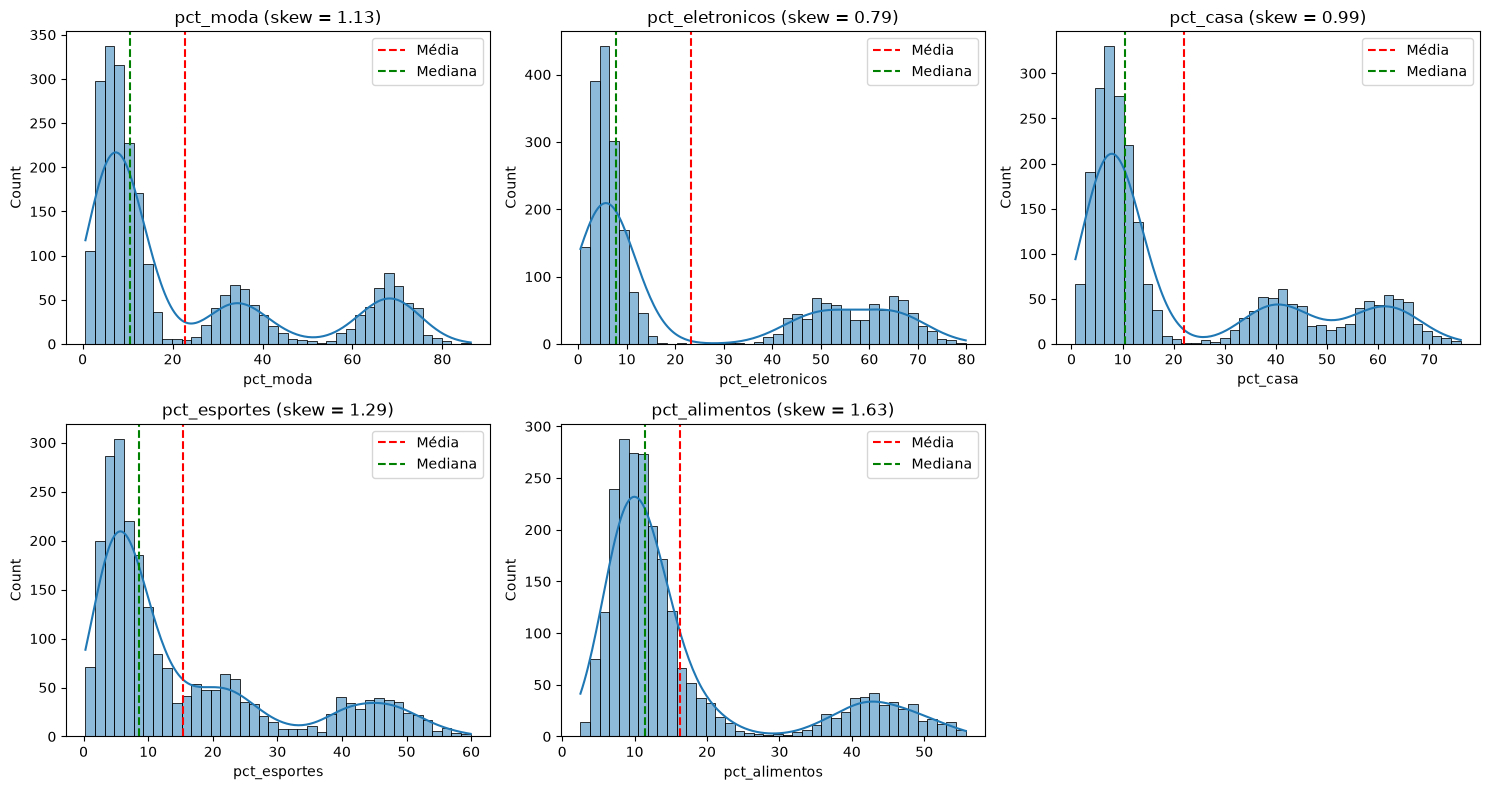

In [57]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, COLS):
    sns.histplot(df[col], kde=True, ax=ax, bins=40)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label="Média") # linha mostrando a média da coluna
    ax.axvline(df[col].median(), color="green", linestyle="--", label="Mediana") # linha mostrando a mediana da coluna
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
    ax.legend()

axes.flat[-1].axis("off") # remove o ultimo axes
plt.tight_layout()
plt.show()

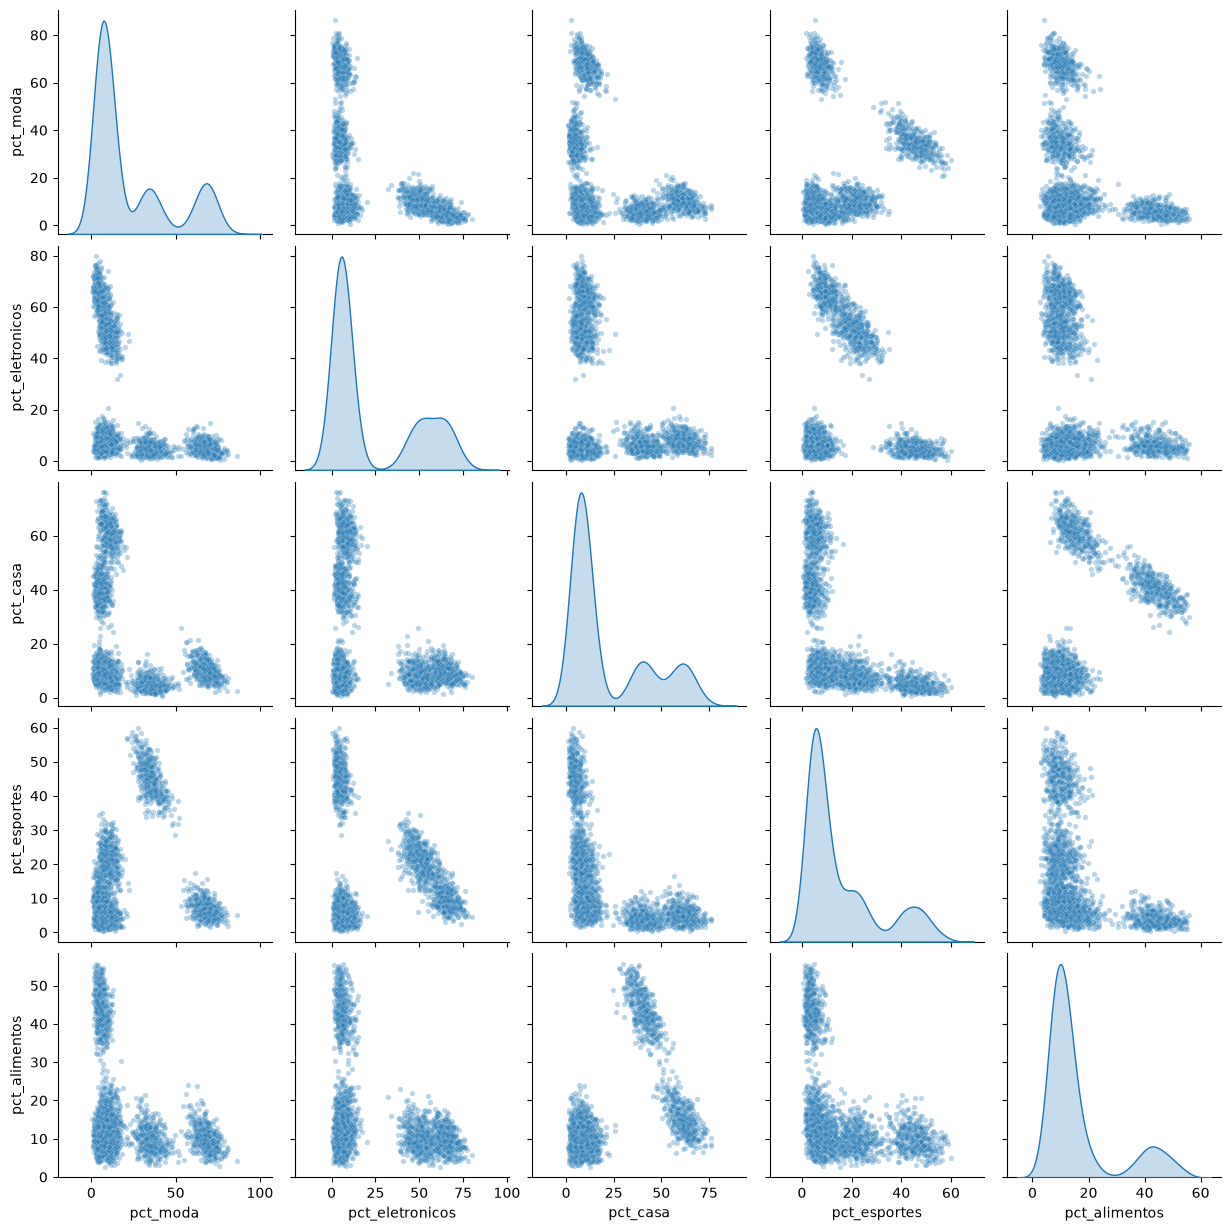

In [58]:
sns.pairplot(df[COLS], diag_kind="kde", plot_kws={"alpha": 0.3, "s": 15})
plt.show()

In [59]:
X = df[COLS].to_numpy()
print(X.shape)

(2400, 5)


### 5. Algoritmo 1: KMeans

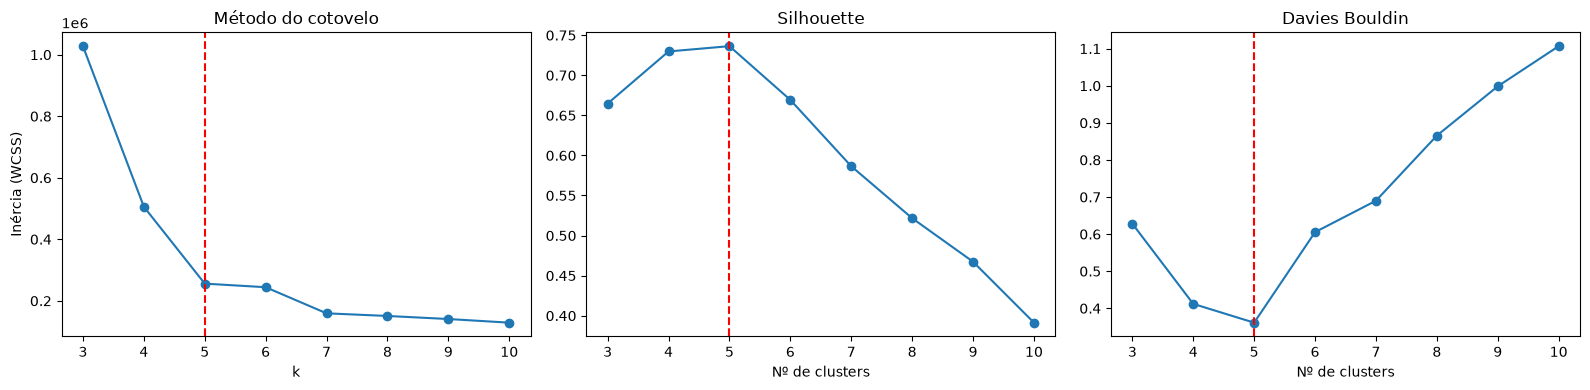

,inertia,silhouette,davies_bouldin
k,,,
3,1027797.398,0.665,0.628
4,505861.038,0.730,0.412
5,255915.130,0.736,0.361
6,244232.797,0.669,0.605
7,159346.585,0.587,0.690
8,150780.641,0.522,0.866
9,140834.867,0.467,0.998
10,128976.330,0.391,1.107


In [60]:
k_results = []
for k in range(3, 11):
    _kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE).fit(X)
    k_results.append({
        "k": k, 
        "inertia": _kmeans.inertia_, 
        "silhouette": silhouette_score(X, _kmeans.labels_),
        "davies_bouldin": davies_bouldin_score(X, _kmeans.labels_)
    })

k_results = pd.DataFrame(k_results).set_index("k")

best_sil = k_results["silhouette"].idxmax()
best_dav = k_results["davies_bouldin"].idxmin()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
k_results["inertia"].plot(marker="o", ax=axes[0], title="Método do cotovelo")
k_results["silhouette"].plot(marker="o", ax=axes[1], title="Silhouette")
k_results["davies_bouldin"].plot(marker="o", ax=axes[2], title="Davies Bouldin")

axes[0].set_ylabel("Inércia (WCSS)")
for i in range(1, 3):
    axes[i].set_xlabel("Nº de clusters")

axes[0].axvline(5, color="red", linestyle="--")
axes[1].axvline(best_sil, color="red", linestyle="--")
axes[2].axvline(best_dav, color="red", linestyle="--")

plt.tight_layout()
plt.show()

best_k = k_results["silhouette"].idxmax()
display(k_results.round(3))

In [82]:
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE).fit(X)
labels = kmeans.labels_

df["cluster"] = labels

print(f"Silhoueta: {silhouette_score(X, labels)}")
print(f"Davies Bouldin: {davies_bouldin_score(X, labels)}")

profile = df.groupby("cluster")[COLS].median().round(1) # perfil baseado na mediana dos dados
profile.insert(0, "n", df["cluster"].value_counts().sort_index()) # quantidade de dados em cada cluster

names = {}
threshold = 30
for c, row in profile[COLS].iterrows():
    d = row[row >= threshold].sort_values(ascending=False)
    names[c] = " + ".join(i.replace("pct_", "") for i in d.index)

profile.insert(1, "profile", profile.index.map(names))
df["profile"] = df["cluster"].map(names)

df.head()

Silhoueta: 0.7363553982716263
Davies Bouldin: 0.3613103878449829


,id_cliente,pct_moda,pct_eletronicos,pct_casa,pct_esportes,pct_alimentos,cluster,profile
0,C000001,8.47,9.03,67.39,4.19,10.93,1,casa
1,C000002,34.93,3.36,4.68,49.38,7.65,0,esportes + moda
2,C000003,1.83,65.62,11.23,8.62,12.70,2,eletronicos
3,C000004,3.90,6.83,59.86,5.88,23.53,1,casa
4,C000005,11.19,44.74,7.65,20.06,16.36,2,eletronicos


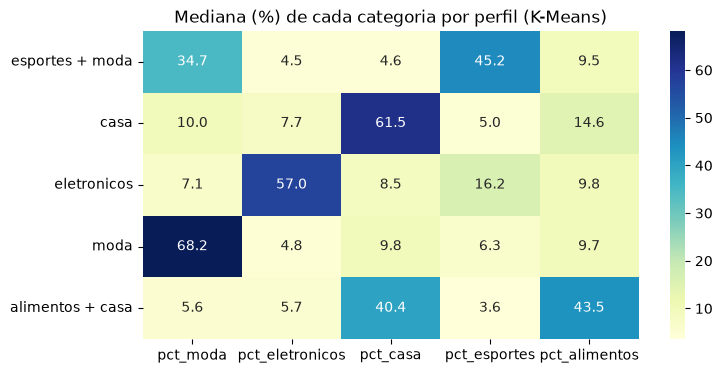

In [83]:
plt.figure(figsize=(8, 4))
sns.heatmap(profile.set_index("profile")[COLS], annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Mediana (%) de cada categoria por perfil (K-Means)")
plt.ylabel("")
plt.show()

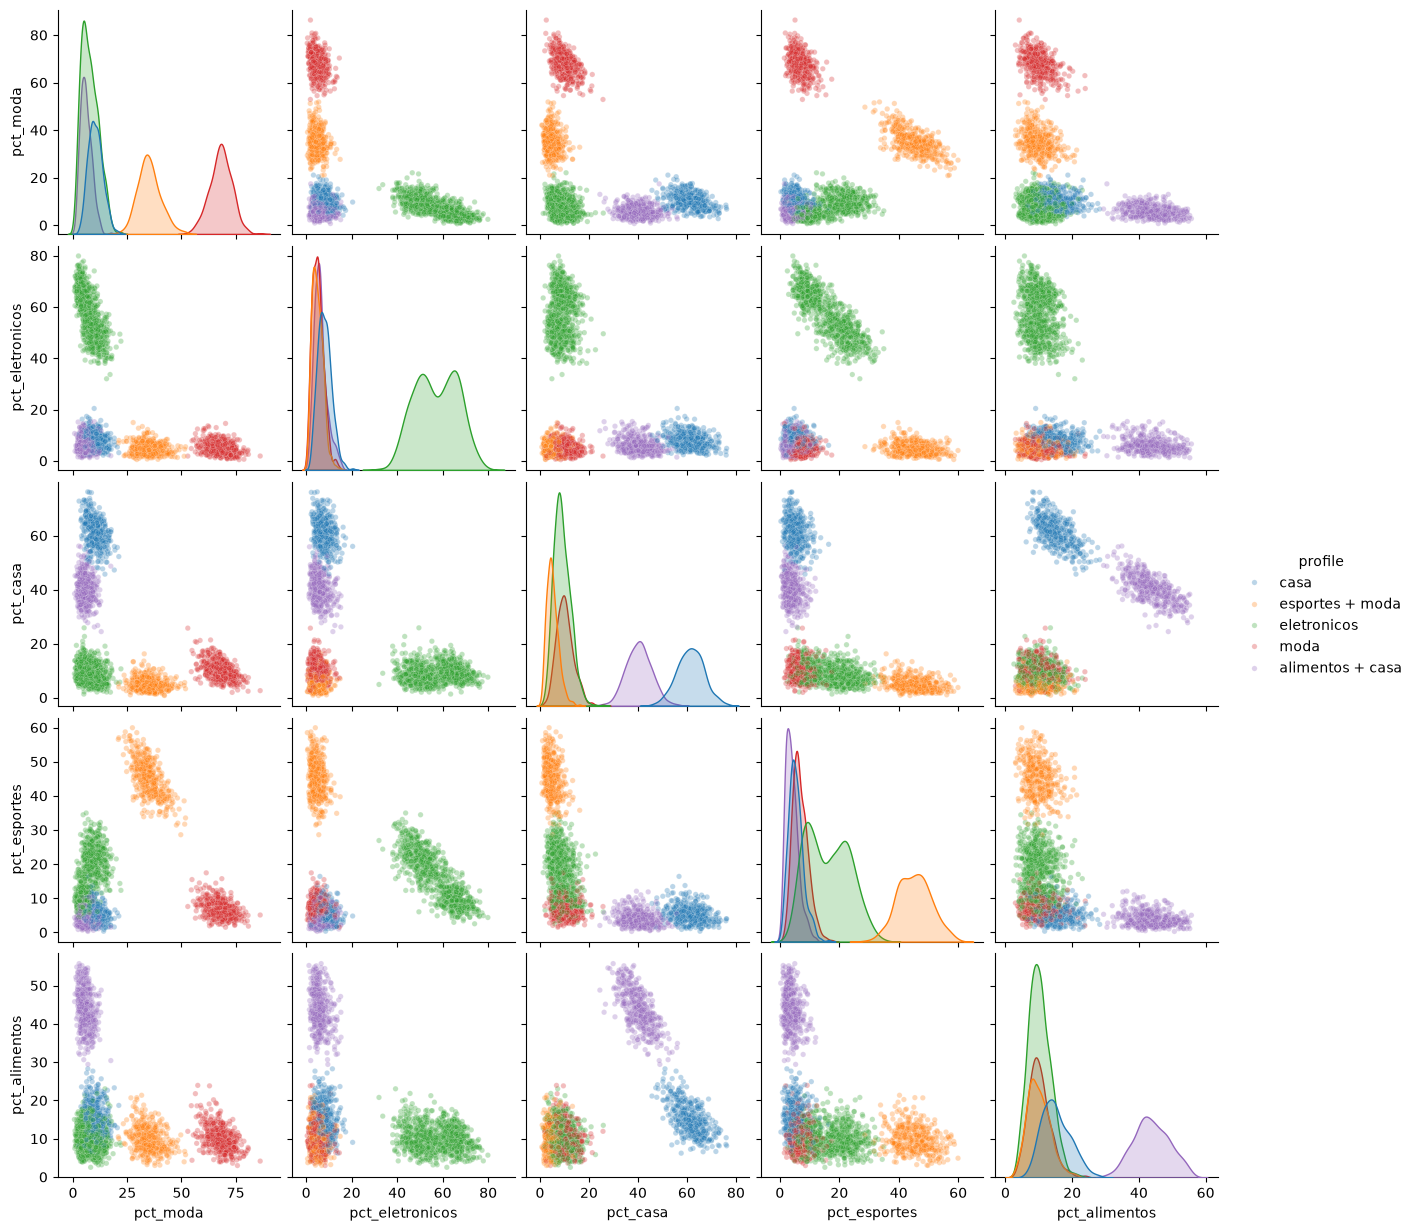

In [86]:
sns.pairplot(df[COLS + ["profile"]], hue="profile", palette="tab10", diag_kind="kde", plot_kws={"alpha": 0.3, "s": 15})
plt.show()

In [91]:
agg_result = []
agg_labels_linkage = {}
for link in ["single", "complete", "average", "ward"]:
    agg = AgglomerativeClustering(n_clusters=5, linkage=link).fit_predict(X)
    agg_labels_linkage[link] = agg
    agg_result.append({"linkage": link, "silhouette": silhouette_score(X, agg), "davies_bouldin": davies_bouldin_score(X, agg)})

display(pd.DataFrame(agg_result).set_index("linkage").round(3))

,silhouette,davies_bouldin
linkage,,
single,0.487,0.908
complete,0.734,0.363
average,0.735,0.363
ward,0.736,0.362


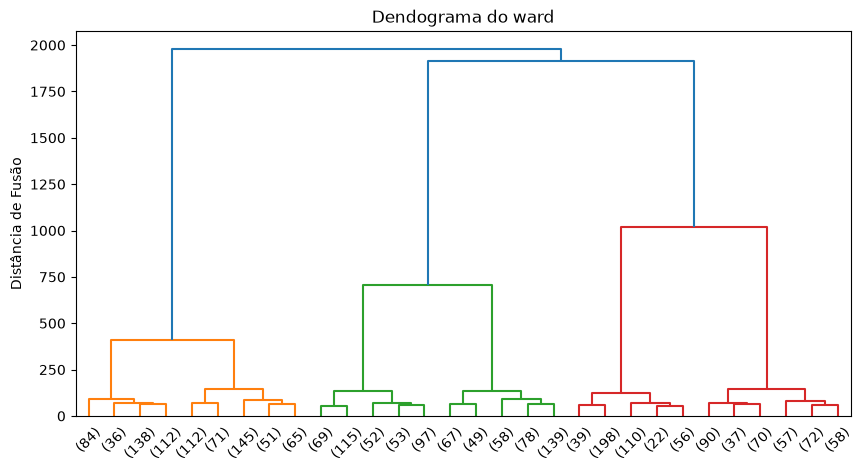

,id_cliente,pct_moda,pct_eletronicos,pct_casa,pct_esportes,pct_alimentos,cluster,profile,cluster_agness
0,C000001,8.47,9.03,67.39,4.19,10.93,1,casa,4
1,C000002,34.93,3.36,4.68,49.38,7.65,0,esportes + moda,2
2,C000003,1.83,65.62,11.23,8.62,12.70,2,eletronicos,0
3,C000004,3.90,6.83,59.86,5.88,23.53,1,casa,4
4,C000005,11.19,44.74,7.65,20.06,16.36,2,eletronicos,0
...,...,...,...,...,...,...,...,...,...
2395,C002396,9.37,13.34,60.82,1.64,14.83,1,casa,4
2396,C002397,7.66,61.60,8.71,8.79,13.24,2,eletronicos,0
2397,C002398,7.66,48.88,15.82,19.53,8.11,2,eletronicos,0
2398,C002399,10.59,53.64,7.60,20.46,7.71,2,eletronicos,0


In [93]:
Z = linkage(X, method="ward")
plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", show_leaf_counts=True)
plt.title("Dendograma do ward")
plt.ylabel("Distância de Fusão")
plt.show()

agg_labels = agg_labels_linkage["ward"]
df["cluster_agness"] = agg_labels

display(df)